In [1]:
from google.colab import files
uploaded = files.upload()

Saving Global_Warming_Cleaned.zip to Global_Warming_Cleaned.zip


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("/content/Global_Warming_Cleaned.zip")

# Basic validation
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Plot appearance
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

df.head()


Dataset shape: (100000, 26)
Missing values: 0
Duplicate rows: 0


,Country,Year,Temperature_Anomaly,CO2_Emissions,Population,Forest_Area,GDP,Renewable_Energy_Usage,Methane_Emissions,Sea_Level_Rise,...,Waste_Management,Per_Capita_Emissions,Industrial_Activity,Air_Pollution_Index,Biodiversity_Index,Ocean_Acidification,Fossil_Fuel_Usage,Energy_Consumption_Per_Capita,Policy_Score,Average_Temperature
0,Country_103,1913,-1.163537,8.876061e+08,1.627978e+08,54.872178,6.139887e+12,76.710013,8.317626e+06,8.111839,...,82.691409,2.285351,4.060975,150.285539,90.073356,8.025470,39.163860,1480.164332,78.870012,20.825292
1,Country_180,1950,-0.432122,4.497517e+08,4.281359e+08,84.051006,2.601447e+12,68.450021,6.206540e+06,42.025915,...,59.322883,17.411668,85.300604,27.305922,88.289837,8.021719,28.252554,1482.730048,32.600905,28.720587
2,Country_93,2014,0.444954,4.579080e+08,4.926732e+08,72.295357,5.192677e+12,36.725699,1.056885e+06,20.953840,...,94.982931,12.039703,83.804880,216.911429,86.936256,7.647408,61.548382,706.918809,37.671300,15.014084
3,Country_15,2020,-1.171616,5.049503e+08,1.252169e+09,17.259684,8.252128e+12,77.547901,1.986813e+06,45.599595,...,62.064250,2.853957,47.014265,35.869182,44.904331,7.569353,82.423750,2616.238324,86.581725,-1.277086
4,Country_107,1964,-0.564038,6.898891e+08,2.932960e+08,44.438605,8.560746e+12,10.019576,3.313252e+06,7.652150,...,84.431279,19.801173,89.379613,284.263093,8.102916,8.015415,29.964450,4975.683780,20.618406,2.861989


Univariate Analysis

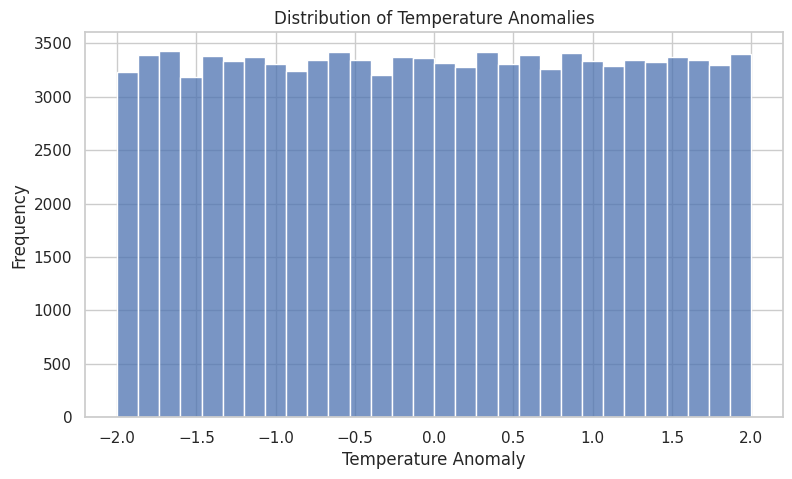

In [3]:

# 1. Histogram — Temperature Anomaly
sns.histplot(data=df, x="Temperature_Anomaly", bins=30, kde=False)
plt.title("Distribution of Temperature Anomalies")
plt.xlabel("Temperature Anomaly")
plt.ylabel("Frequency")
plt.show()


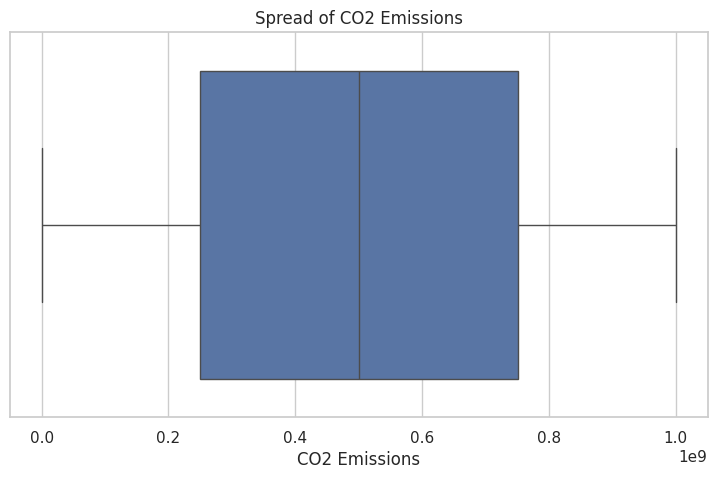

In [4]:

# 2. Box plot — CO2 Emissions
sns.boxplot(data=df, x="CO2_Emissions")
plt.title("Spread of CO2 Emissions")
plt.xlabel("CO2 Emissions")
plt.show()


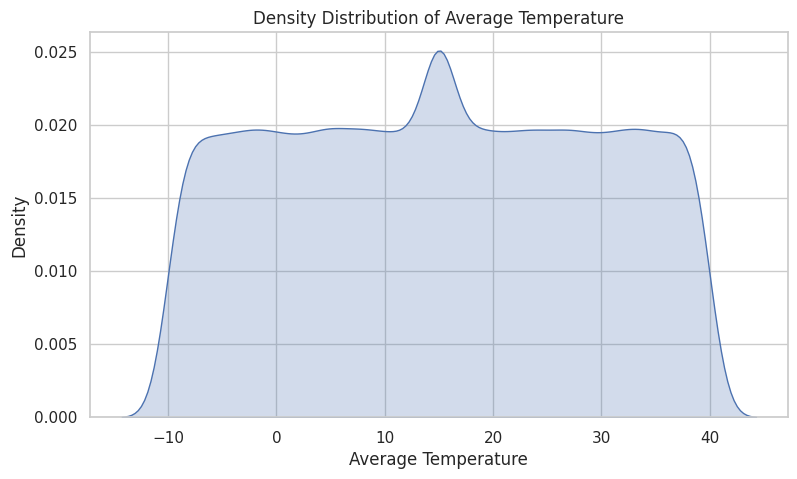

In [5]:

# 3. KDE plot — Average Temperature
sns.kdeplot(data=df, x="Average_Temperature", fill=True)
plt.title("Density Distribution of Average Temperature")
plt.xlabel("Average Temperature")
plt.show()


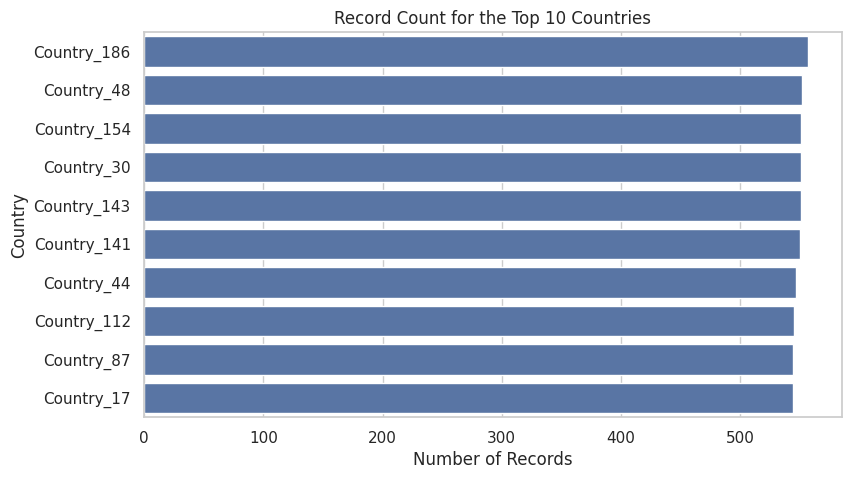

In [6]:

# 4. Count plot — Country
top_countries = df["Country"].value_counts().head(10).index

sns.countplot(
    data=df[df["Country"].isin(top_countries)],
        y="Country",
            order=top_countries
            )
plt.title("Record Count for the Top 10 Countries")
plt.xlabel("Number of Records")
plt.ylabel("Country")
plt.show()


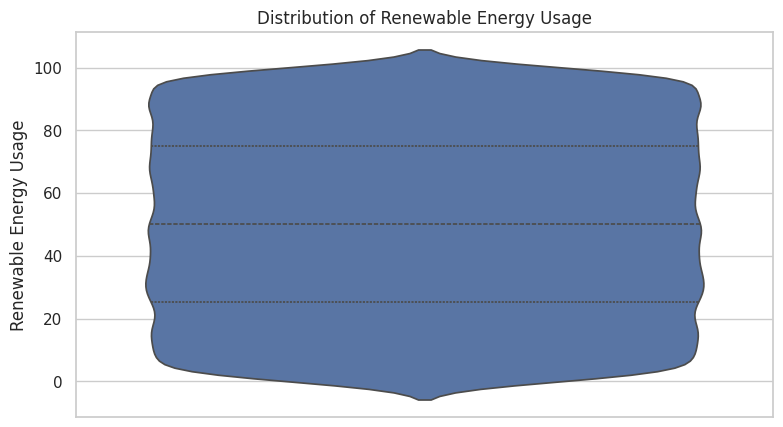

In [7]:

# 5. Violin plot — Renewable Energy Usage
sns.violinplot(data=df, y="Renewable_Energy_Usage", inner="quartile")
plt.title("Distribution of Renewable Energy Usage")
plt.ylabel("Renewable Energy Usage")
plt.show()


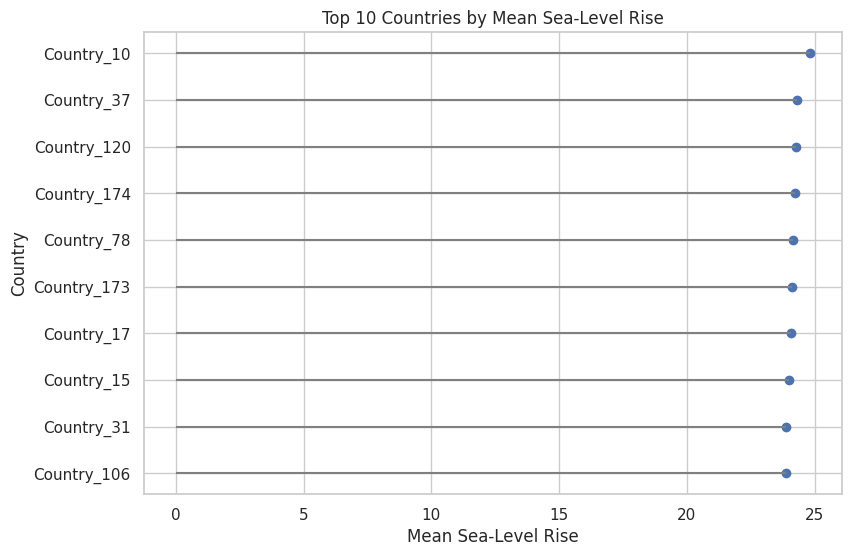

In [8]:

# 6. Lollipop chart — Top 10 countries by mean sea-level rise
country_means = (
    df.groupby("Country")["Sea_Level_Rise"]
          .mean()
                .sort_values()
                      .tail(10)
                      )

plt.figure(figsize=(9, 6))
plt.hlines(
                          y=country_means.index,
                              xmin=0,
                                  xmax=country_means.values,
                                      color="gray"
                                      )
plt.scatter(country_means.values, country_means.index)
plt.title("Top 10 Countries by Mean Sea-Level Rise")
plt.xlabel("Mean Sea-Level Rise")
plt.ylabel("Country")
plt.show()


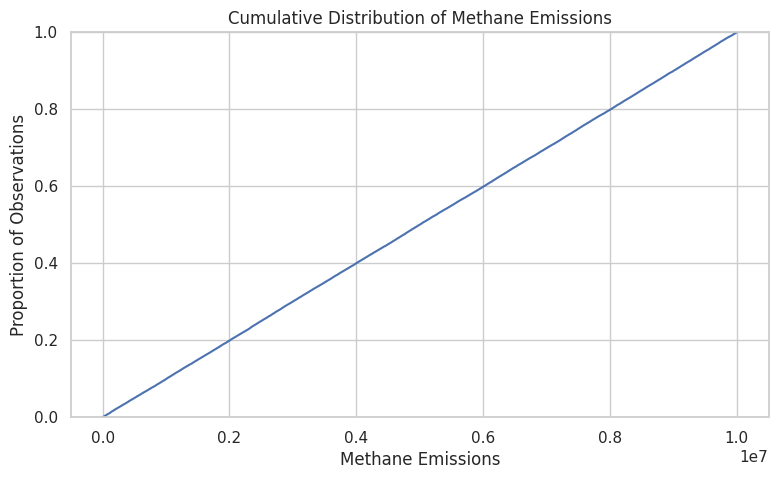

In [9]:

# 7. ECDF plot — Methane Emissions
sns.ecdfplot(data=df, x="Methane_Emissions")
plt.title("Cumulative Distribution of Methane Emissions")
plt.xlabel("Methane Emissions")
plt.ylabel("Proportion of Observations")
plt.show()


Bivariate Analysis

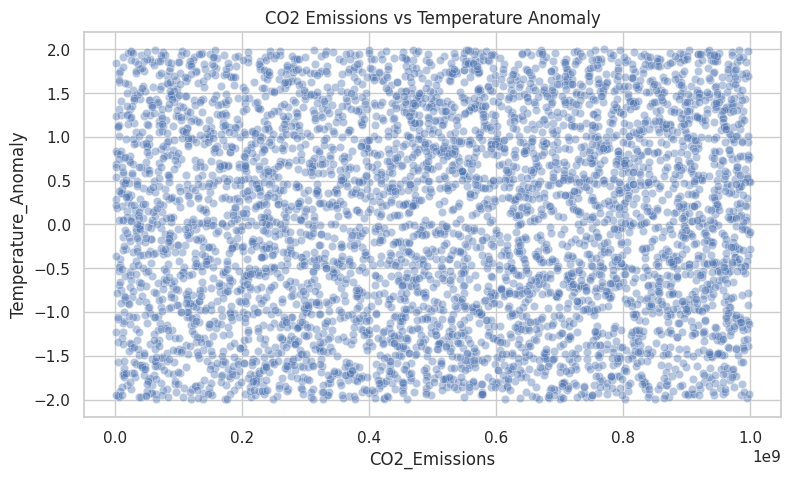

In [10]:

# 1. Scatter plot — CO2 Emissions vs Temperature Anomaly
sample = df.sample(n=min(5000, len(df)), random_state=42)

sns.scatterplot(
    data=sample,
        x="CO2_Emissions",
            y="Temperature_Anomaly",
                alpha=0.4
                )
plt.title("CO2 Emissions vs Temperature Anomaly")
plt.show()


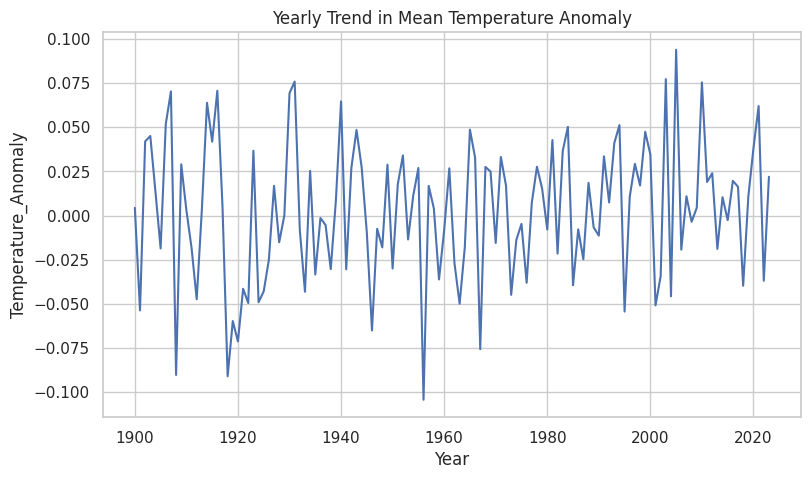

In [11]:

# 2. Line plot — Year vs mean Temperature Anomaly
yearly = df.groupby("Year", as_index=False)["Temperature_Anomaly"].mean()

sns.lineplot(
    data=yearly,
        x="Year",
            y="Temperature_Anomaly"
            )
plt.title("Yearly Trend in Mean Temperature Anomaly")
plt.show()


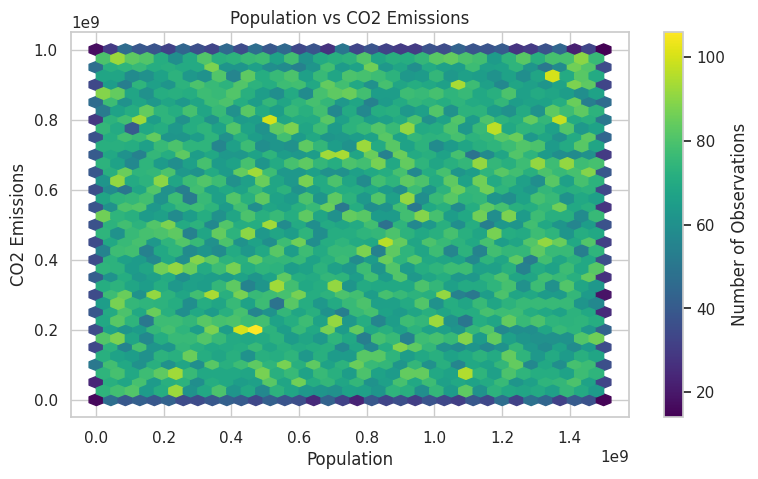

In [12]:

# 3. Hexbin plot — Population vs CO2 Emissions
plt.figure(figsize=(9, 5))
plt.hexbin(
    df["Population"],
        df["CO2_Emissions"],
            gridsize=35,
                mincnt=1,
                    cmap="viridis"
                    )
plt.colorbar(label="Number of Observations")
plt.title("Population vs CO2 Emissions")
plt.xlabel("Population")
plt.ylabel("CO2 Emissions")
plt.show()


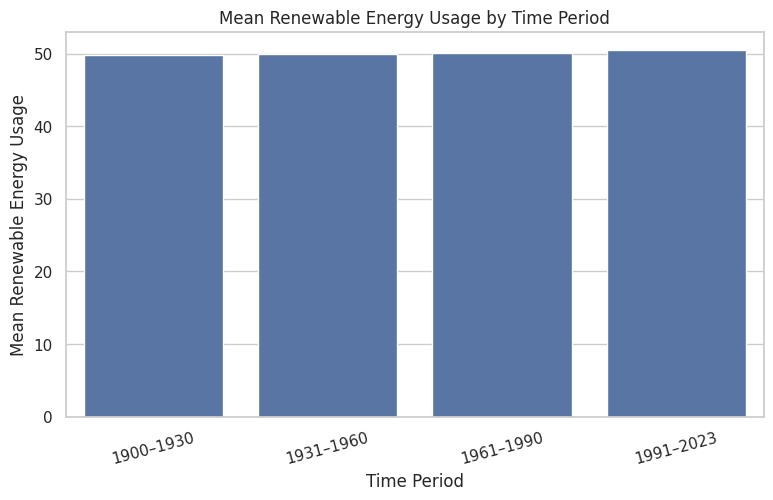

In [13]:

# 4. Grouped bar chart — Time period vs Renewable Energy Usage
df["Year_Period"] = pd.cut(
    df["Year"],
        bins=[1899, 1930, 1960, 1990, 2023],
            labels=["1900–1930", "1931–1960", "1961–1990", "1991–2023"]
            )

period_means = (
                df.groupby("Year_Period", observed=False)["Renewable_Energy_Usage"]
                      .mean()
                            .reset_index()
                            )

sns.barplot(
                                data=period_means,
                                    x="Year_Period",
                                        y="Renewable_Energy_Usage"
                                        )
plt.title("Mean Renewable Energy Usage by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Mean Renewable Energy Usage")
plt.xticks(rotation=15)
plt.show()


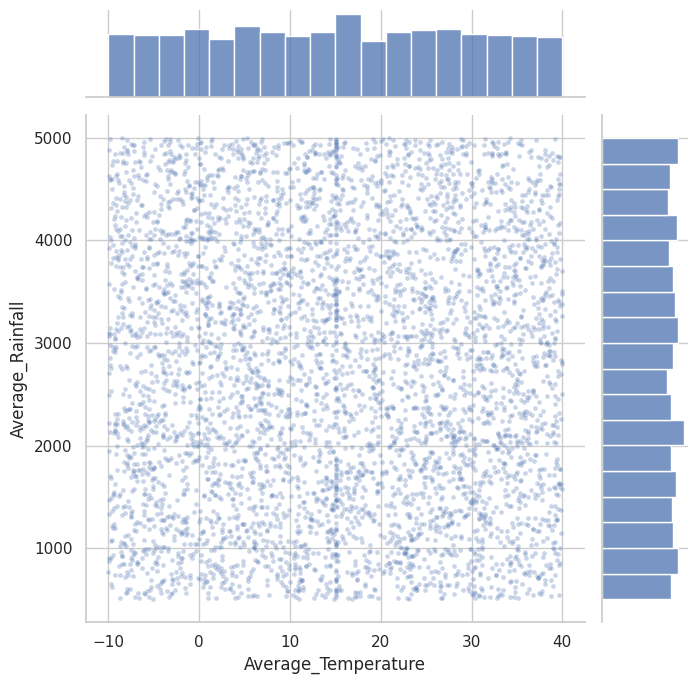

In [14]:

# 5. Joint plot — Average Temperature vs Average Rainfall
sns.jointplot(
    data=sample,
        x="Average_Temperature",
            y="Average_Rainfall",
                kind="scatter",
                    height=7,
                        joint_kws={"alpha": 0.3, "s": 12}
                        )
plt.show()


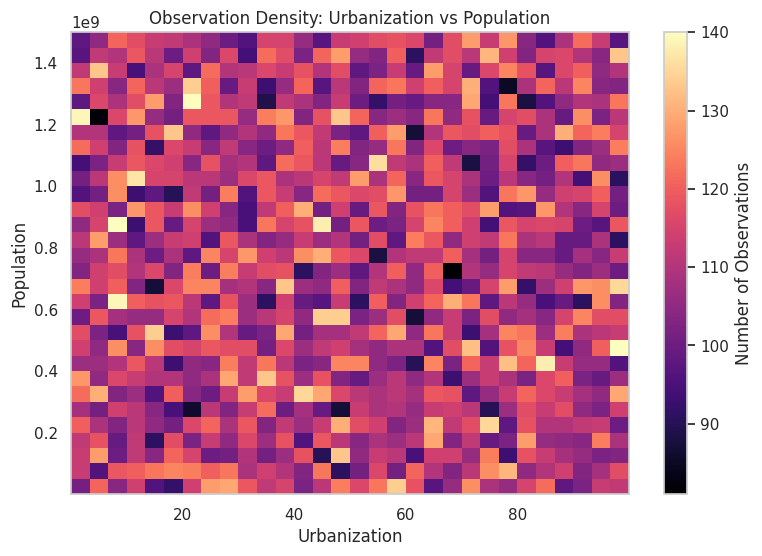

In [15]:

# 6. 2D binned heatmap — Urbanization vs Population
plt.figure(figsize=(9, 6))

plt.hist2d(
    df["Urbanization"],
        df["Population"],
            bins=30,
                cmap="magma"
                )

plt.colorbar(label="Number of Observations")
plt.title("Observation Density: Urbanization vs Population")
plt.xlabel("Urbanization")
plt.ylabel("Population")
plt.show()

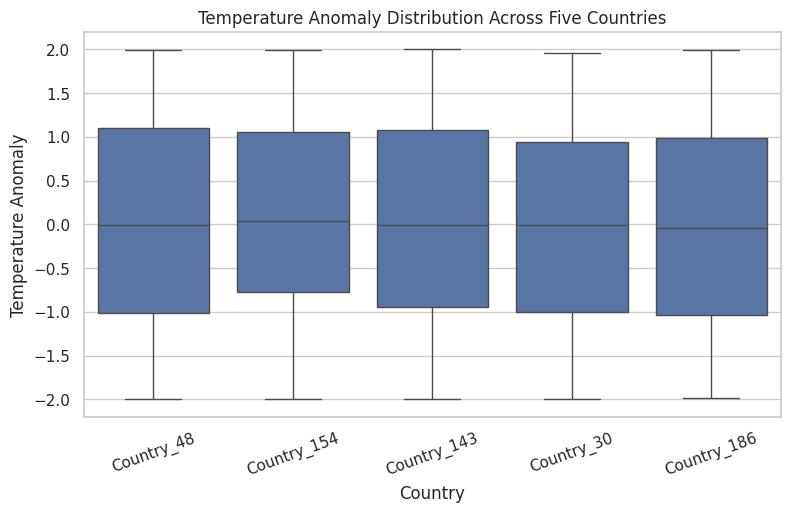

In [16]:

# 7. Grouped box plot — Country vs Temperature Anomaly
top5 = df["Country"].value_counts().head(5).index
country_sample = df[df["Country"].isin(top5)]

sns.boxplot(
    data=country_sample,
        x="Country",
            y="Temperature_Anomaly"
            )

plt.title("Temperature Anomaly Distribution Across Five Countries")
plt.xlabel("Country")
plt.ylabel("Temperature Anomaly")
plt.xticks(rotation=20)
plt.show()
